## Milestone 2: Exploratory Data Analysis
## Predicting Food Delivery Times

Claudia Galdamez

DSC355-T301 Predictive Analytics (2271-1)

9/20/2026

## Introduction

For this project, I am using a food delivery dataset from Kaggle to look at what can affect delivery times (denkuznetz, n.d.). The dataset includes things like distance, weather, traffic, time of day, vehicle type, food preparation time, and the courier’s experience.

The target variable for my project is `Delivery_Time_min`. My hypothesis is that distance, traffic, and preparation time will probably have the biggest effect on delivery time.

In this milestone, I will look at the variables, missing values, distributions, outliers, correlations, and relationships between the features and the target.

In [ ]:
# Import libraries for data analysis and visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

I will use Pandas to work with the dataset and look at basic statistics. NumPy will be used for any calculations I need, and Matplotlib will help me create graphs for better data understanding.

In [ ]:
# Load the Food Delivery Dataset

df = pd.read_csv('/content/Food_Delivery_Times.csv')

df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


Each row in the dataset is one food delivery order. It includes information like the delivery distance, weather, traffic, time of day, vehicle type, preparation time, courier experience, and how long the delivery took. The dataset has a mix of numbers and categories. The main variable I will be focusing on is Delivery_Time_min.


In [ ]:
# Check the Size of the Dataset

df.shape

(1000, 9)

The dataset has 1,000 rows and 9 columns, so I have 1,000 food delivery orders to use for my analysis.

In [ ]:
# Check the Column Names

df.columns

Index(['Order_ID', 'Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day',
       'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs',
       'Delivery_Time_min'],
      dtype='object')

In [ ]:
# Check Data Types and Non-Null Values

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB


The dataset has both numerical and categorical variables. The numerical variables are `Order_ID`, `Distance_km`, `Preparation_Time_min`, `Courier_Experience_yrs`, and `Delivery_Time_min`. The categorical variables are `Weather`, `Traffic_Level`, `Time_of_Day`, and `Vehicle_Type`. My target variable is `Delivery_Time_min`. Even though `Order_ID` is a number, it is only used to identify each order, so I do not think it will be useful for predicting delivery time.


In [ ]:
# Check for Missing Values

df.isnull().sum()

,0
Order_ID,0
Distance_km,0
Weather,30
Traffic_Level,30
Time_of_Day,30
Vehicle_Type,0
Preparation_Time_min,0
Courier_Experience_yrs,30
Delivery_Time_min,0


There are 30 missing values in Weather, Traffic_Level, Time_of_Day, and Courier_Experience_yrs. With 1,000 rows total, 30 missing values is a small amount. All of the other columns have complete data.

In [ ]:
# Descriptive Statistics for Numerical Variables

df.describe()

,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.000000,1000.000000,1000.000000,970.000000,1000.000000
mean,500.500000,10.059970,16.982000,4.579381,56.732000
std,288.819436,5.696656,7.204553,2.914394,22.070915
min,1.000000,0.590000,5.000000,0.000000,8.000000
25%,250.750000,5.105000,11.000000,2.000000,41.000000
50%,500.500000,10.190000,17.000000,5.000000,55.500000
75%,750.250000,15.017500,23.000000,7.000000,71.000000
max,1000.000000,19.990000,29.000000,9.000000,153.000000


I used the statistics to get a better idea of what a typical delivery looks like. The average distance is about 10 km, preparation time is about 17 minutes, and couriers have around 4.6 years of experience.

The average delivery time is about 57 minutes, and the median is about 56 minutes. Delivery times range from 8 to 153 minutes. Since 75% of the deliveries take 71 minutes or less, 153 minutes seems pretty high. I want to look at the graphs next to see if there are any outliers.

I also want to see if distance and preparation time have a connection to how long a delivery takes.


I used Pandas to calculate descriptive statistics and summarize the numerical variables (pandas development team, n.d.).


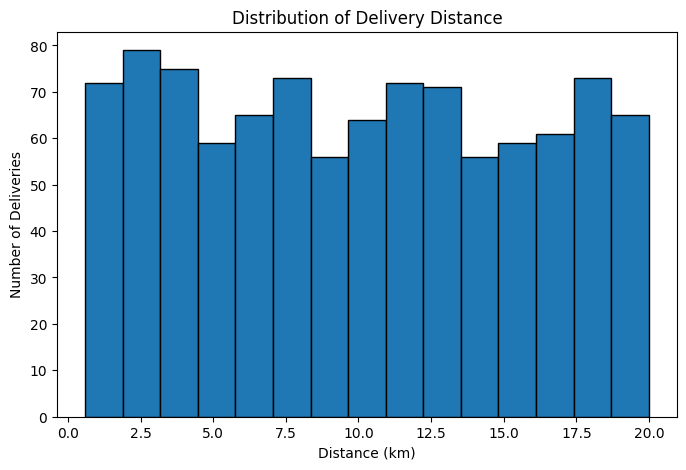

In [ ]:
# Distribution of Delivery Distance

plt.figure(figsize=(8, 5))

plt.hist(df['Distance_km'], bins=15, edgecolor='black')

plt.title('Distribution of Delivery Distance')
plt.xlabel('Distance (km)')
plt.ylabel('Number of Deliveries')

plt.show()

The delivery distances are spread pretty evenly from less than 1 km to about 20 km. There does not seem to be one distance range that is much more common than the others, and I do not see any obvious unusual values.

Since distance is part of my hypothesis, I still want to compare it with delivery time to see if longer distances lead to longer deliveries.


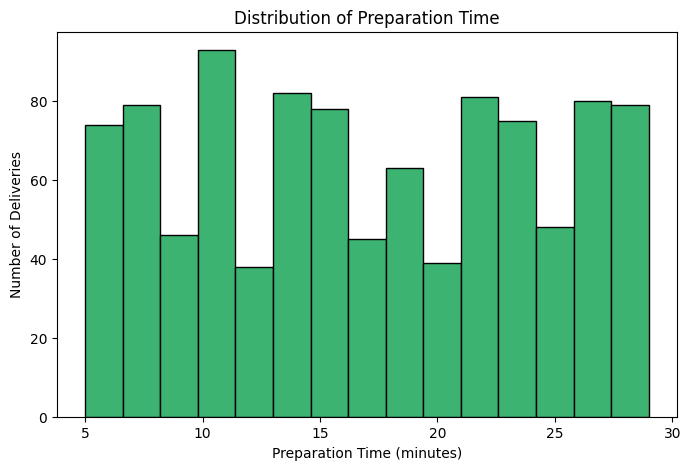

In [ ]:
# Distribution of Preparation Time

plt.figure(figsize=(8, 5))

plt.hist(df['Preparation_Time_min'], bins=15,
         color='mediumseagreen', edgecolor='black')

plt.title('Distribution of Preparation Time')
plt.xlabel('Preparation Time (minutes)')
plt.ylabel('Number of Deliveries')

plt.show()

Preparation times range from about 5 to 29 minutes and are spread out across the range. Some times show up more than others, but I do not see any obvious outliers.

I also want to compare preparation time with delivery time to see if longer preparation times are connected to longer deliveries.


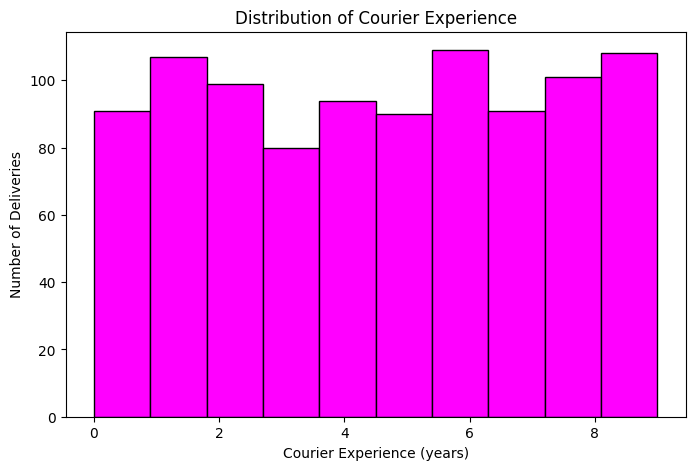

In [ ]:
# Distribution of Courier Experience

plt.figure(figsize=(8, 5))

plt.hist(df['Courier_Experience_yrs'].dropna(), bins=10,
         color='magenta', edgecolor='black')

plt.title('Distribution of Courier Experience')
plt.xlabel('Courier Experience (years)')
plt.ylabel('Number of Deliveries')

plt.show()

Courier experience ranges from 0 to 9 years and is pretty spread out across the different experience levels. There does not seem to be one experience level that is much more common than the others.

I want to compare courier experience with delivery time to see if more experienced couriers tend to make faster deliveries.


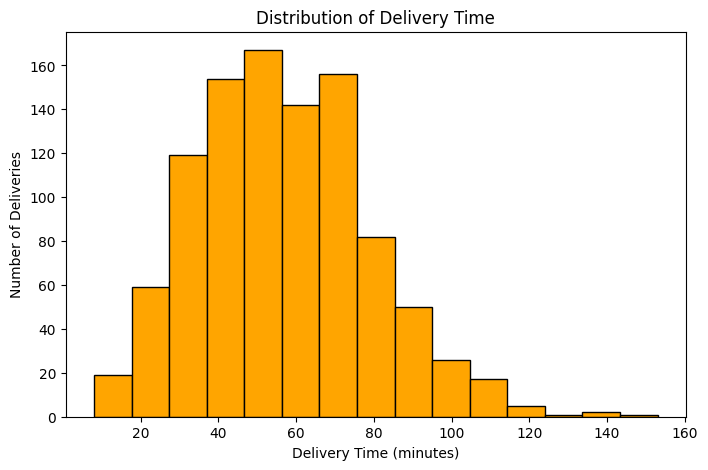

In [ ]:
# Distribution of Delivery Time

plt.figure(figsize=(8, 5))

plt.hist(df['Delivery_Time_min'], bins=15,
         color='orange', edgecolor='black')

plt.title('Distribution of Delivery Time')
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Number of Deliveries')

plt.show()

Most delivery times are between about 30 and 80 minutes. There are fewer deliveries as the delivery time gets longer. Only a few deliveries are over 120 minutes, so I want to use a boxplot to check for outliers.


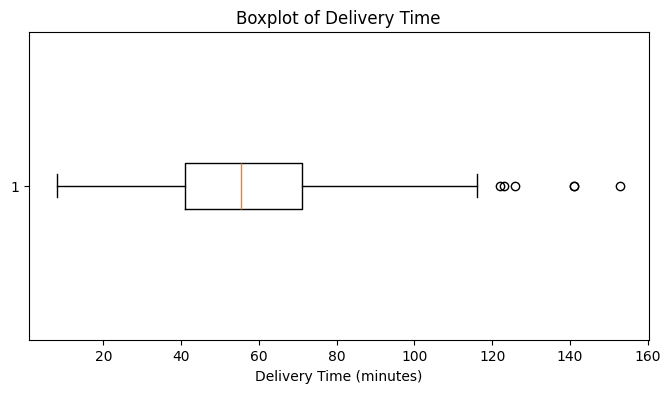

In [ ]:
# Boxplot of Delivery Time

plt.figure(figsize=(8, 4))

plt.boxplot(df['Delivery_Time_min'], vert=False)

plt.title('Boxplot of Delivery Time')
plt.xlabel('Delivery Time (minutes)')

plt.show()

The boxplot confirms that there are not many unusually long delivery times. Most of the data falls below about 120 minutes, but several deliveries above this range are shown as possible outliers. The highest delivery time is around 153 minutes.

I will keep these values for now because they could be real deliveries affected by distance, traffic, weather, or preparation time.

In [ ]:
# Distribution of Weather Conditions

weather_counts = df['Weather'].value_counts()

weather_counts

,count
Weather,
Clear,470
Rainy,204
Foggy,103
Snowy,97
Windy,96


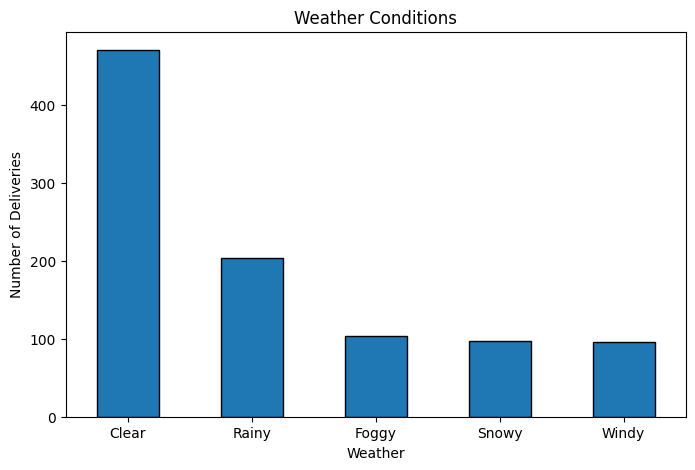

In [ ]:
# Bar Chart of Weather Conditions

weather_counts.plot(kind='bar', figsize=(8, 5), edgecolor='black')

plt.title('Weather Conditions')
plt.xlabel('Weather')
plt.ylabel('Number of Deliveries')
plt.xticks(rotation=0)

plt.show()

Clear weather is the most common with 470 deliveries, followed by rainy weather with 204. The other weather conditions have around 100 deliveries each.

Since some weather conditions have more deliveries than others, I will keep this in mind when comparing weather with delivery time.

In [ ]:
# Check Remaining Categorical Variables

print("Traffic Level:")
print(df['Traffic_Level'].value_counts())

print("\nTime of Day:")
print(df['Time_of_Day'].value_counts())

print("\nVehicle Type:")
print(df['Vehicle_Type'].value_counts())

Traffic Level:
Traffic_Level
Medium    390
Low       383
High      197
Name: count, dtype: int64

Time of Day:
Time_of_Day
Morning      308
Evening      293
Afternoon    284
Night         85
Name: count, dtype: int64

Vehicle Type:
Vehicle_Type
Bike       503
Scooter    302
Car        195
Name: count, dtype: int64


Most deliveries have medium or low traffic, and fewer have high traffic. There are also fewer deliveries at night compared to the other times of day. Bikes are used the most, followed by scooters and cars.

Since some groups have more deliveries than others, I will keep that in mind when I compare them with delivery time.


In [ ]:
# Check Unique Values in Each Column

df.nunique()

,0
Order_ID,1000
Distance_km,785
Weather,5
Traffic_Level,3
Time_of_Day,4
Vehicle_Type,3
Preparation_Time_min,25
Courier_Experience_yrs,10
Delivery_Time_min,108


In [ ]:
# Check for Duplicate Rows

df.duplicated().sum()

np.int64(0)

Order_ID has 1,000 unique values, so it is only being used to identify each order and would not be useful for predicting delivery time. I also checked for duplicate rows and found none.

In [ ]:
# Correlation Between Numerical Variables

numeric_df = df[
    ['Distance_km',
     'Preparation_Time_min',
     'Courier_Experience_yrs',
     'Delivery_Time_min']
]

correlation = numeric_df.corr()

correlation.round(2)

,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
Distance_km,1.00,-0.01,-0.01,0.78
Preparation_Time_min,-0.01,1.00,-0.03,0.31
Courier_Experience_yrs,-0.01,-0.03,1.00,-0.09
Delivery_Time_min,0.78,0.31,-0.09,1.00


Distance has the strongest relationship with delivery time at 0.78. Preparation time is 0.31, so it has some relationship too. Courier experience is only -0.09, so it does not seem to make much of a difference.

So far, distance and preparation time match what I expected. I still need to look at traffic next.

I used the Pandas corr() function to examine the relationships between the numerical variables (pandas development team, n.d.).

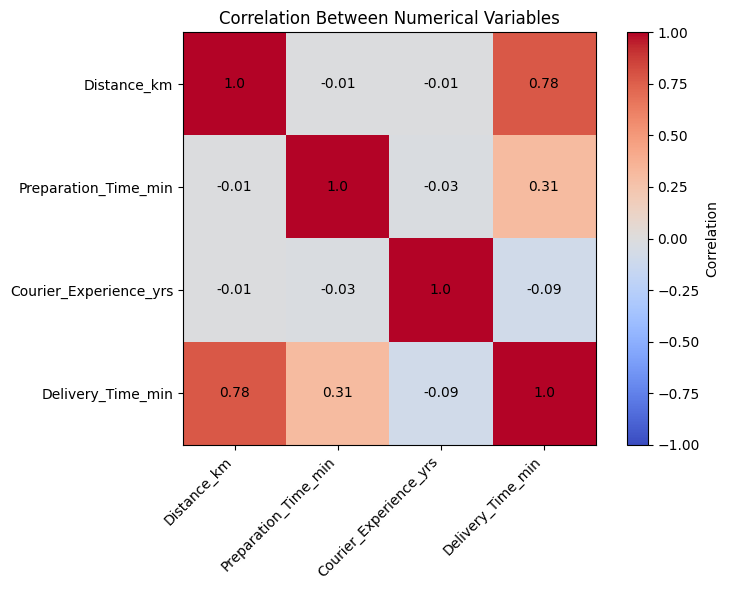

In [ ]:
# Correlation Heatmap

plt.figure(figsize=(8, 6))

plt.imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation')

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha='right'
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(
            j, i,
            round(correlation.iloc[i, j], 2),
            ha='center',
            va='center'
        )

plt.title('Correlation Between Numerical Variables')
plt.tight_layout()
plt.show()

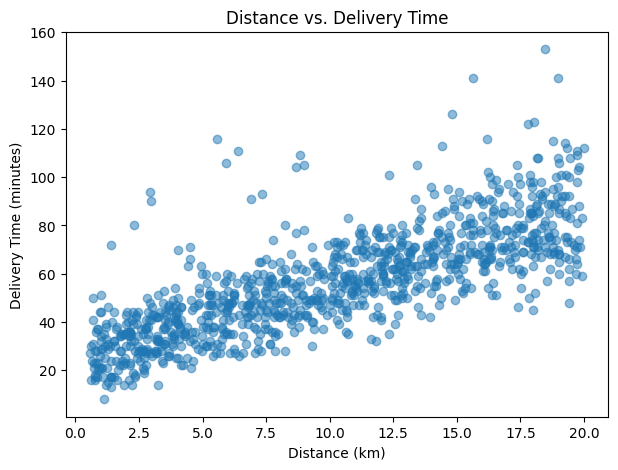

In [ ]:
# Distance vs. Delivery Time

plt.figure(figsize=(7, 5))
plt.scatter(df['Distance_km'], df['Delivery_Time_min'], alpha=0.5)

plt.title('Distance vs. Delivery Time')
plt.xlabel('Distance (km)')
plt.ylabel('Delivery Time (minutes)')

plt.show()

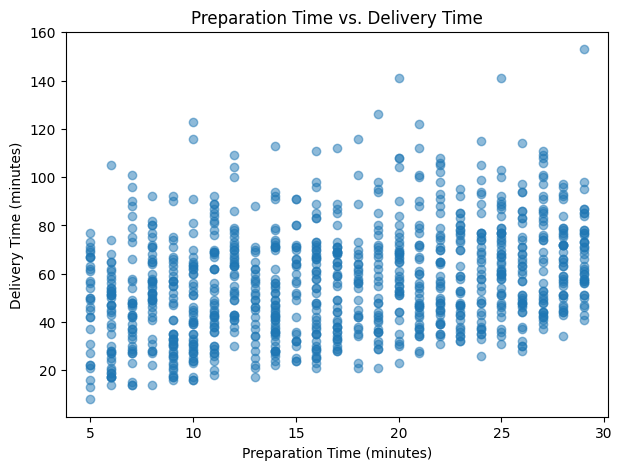

In [ ]:
# Preparation Time vs. Delivery Time

plt.figure(figsize=(7, 5))
plt.scatter(df['Preparation_Time_min'], df['Delivery_Time_min'], alpha=0.5)

plt.title('Preparation Time vs. Delivery Time')
plt.xlabel('Preparation Time (minutes)')
plt.ylabel('Delivery Time (minutes)')

plt.show()

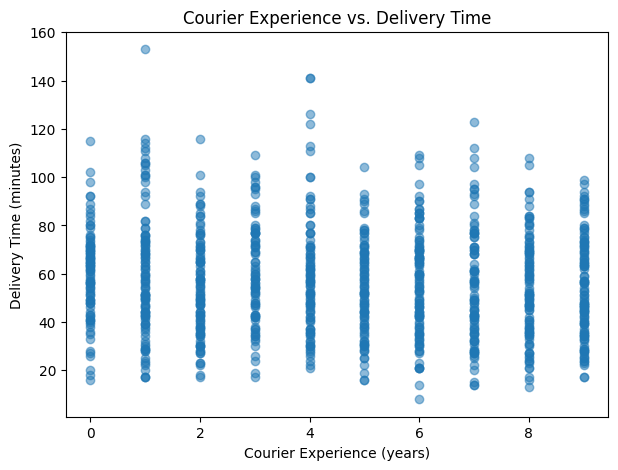

In [ ]:
# Courier Experience vs. Delivery Time

plt.figure(figsize=(7, 5))
plt.scatter(df['Courier_Experience_yrs'], df['Delivery_Time_min'], alpha=0.5)

plt.title('Courier Experience vs. Delivery Time')
plt.xlabel('Courier Experience (years)')
plt.ylabel('Delivery Time (minutes)')

plt.show()

Distance has the clearest relationship with delivery time. As the distance gets longer, delivery time usually gets longer too. Preparation time also shows a similar pattern, but not as much.

Courier experience does not show much of a pattern. Based on these graphs, distance looks like it could be more useful when predicting delivery time.


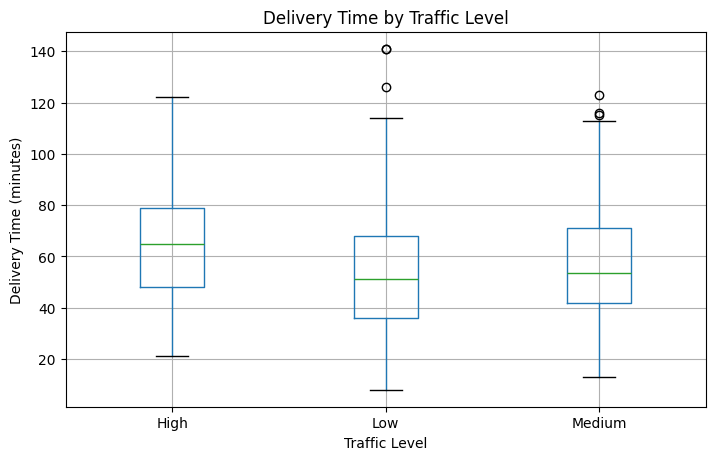

In [ ]:
# Delivery Time by Traffic Level

df.boxplot(
    column='Delivery_Time_min',
    by='Traffic_Level',
    figsize=(8, 5)
)

plt.title('Delivery Time by Traffic Level')
plt.suptitle('')
plt.xlabel('Traffic Level')
plt.ylabel('Delivery Time (minutes)')

plt.show()

Deliveries during high traffic usually take longer than deliveries during low or medium traffic. This matches what I expected about traffic affecting delivery time.


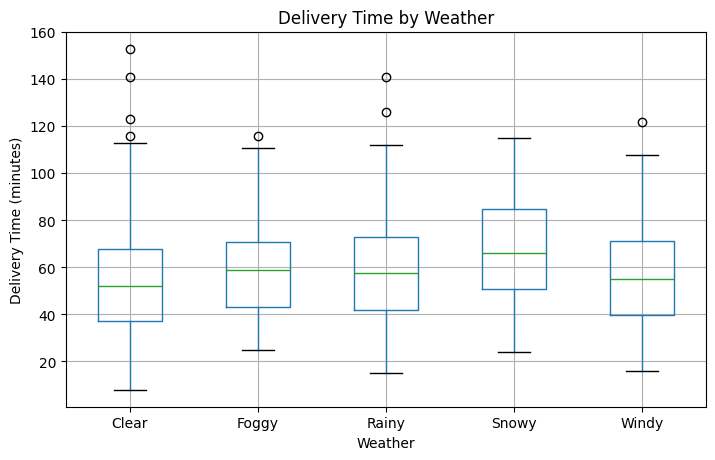

In [ ]:
# Delivery Time by Weather

df.boxplot(
    column='Delivery_Time_min',
    by='Weather',
    figsize=(8, 5)
)

plt.title('Delivery Time by Weather')
plt.suptitle('')
plt.xlabel('Weather')
plt.ylabel('Delivery Time (minutes)')

plt.show()

Weather also appears to affect delivery time. Snowy weather has the highest typical delivery time, while clear weather has the lowest. This suggests that weather may also be useful when predicting delivery time.

I used Matplotlib to create histograms, boxplots, scatterplots, and other visualizations used in the EDA (Matplotlib development team, n.d.).

## Hypothesis

My original hypothesis was that distance, traffic, and preparation time would have the strongest relationships with delivery time.

The results support my hypothesis. Distance had the strongest correlation at 0.78, while preparation time had a smaller correlation of 0.31. Deliveries during high traffic also took longer. Weather may also be important, especially when it is snowy.

Based on these results, I would keep distance, preparation time, traffic, and weather when building the model.


## Modeling strategy

The EDA helped me identify a few things I will need to consider before modeling. Order_ID should be removed because it is only an identifier. I will also need to handle the missing values in weather, traffic level, time of day, and courier experience.

Distance seems to be the most useful for predicting delivery time, but preparation time, traffic, and weather could also be important.

I also found a few outliers in delivery time, but I will keep them for now since they could be real deliveries.

## EDA Summary

Overall, the EDA helped me see which factors seem to matter most for delivery time. Distance had the strongest relationship, while preparation time, traffic, and weather also showed some differences in delivery times.

Before building the model, I will need to handle the missing values, remove Order_ID, and prepare the categorical variables so they can be used in the model.

## References

Matplotlib development team. (n.d.). *Plot types*. Matplotlib. https://matplotlib.org/stable/plot_types/

pandas development team. (n.d.). *pandas.DataFrame.corr*. pandas. https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html

pandas development team. (n.d.). *pandas.DataFrame.describe*. pandas. https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html

denkuznetz. (n.d.). *Food delivery time prediction* [Data set]. Kaggle. https://www.kaggle.com/datasets/denkuznetz/food-delivery-time-prediction
